In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


In [2]:

iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("Dataset shape:", X.shape)
print("\nFirst five rows:")
display(X.head())

print("\nTarget classes:", iris.target_names)
print("\nMissing values:")
print(X.isnull().sum())


Dataset shape: (150, 4)

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target classes: ['setosa' 'versicolor' 'virginica']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [4]:

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, dt_predictions, target_names=iris.target_names))


Decision Tree Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



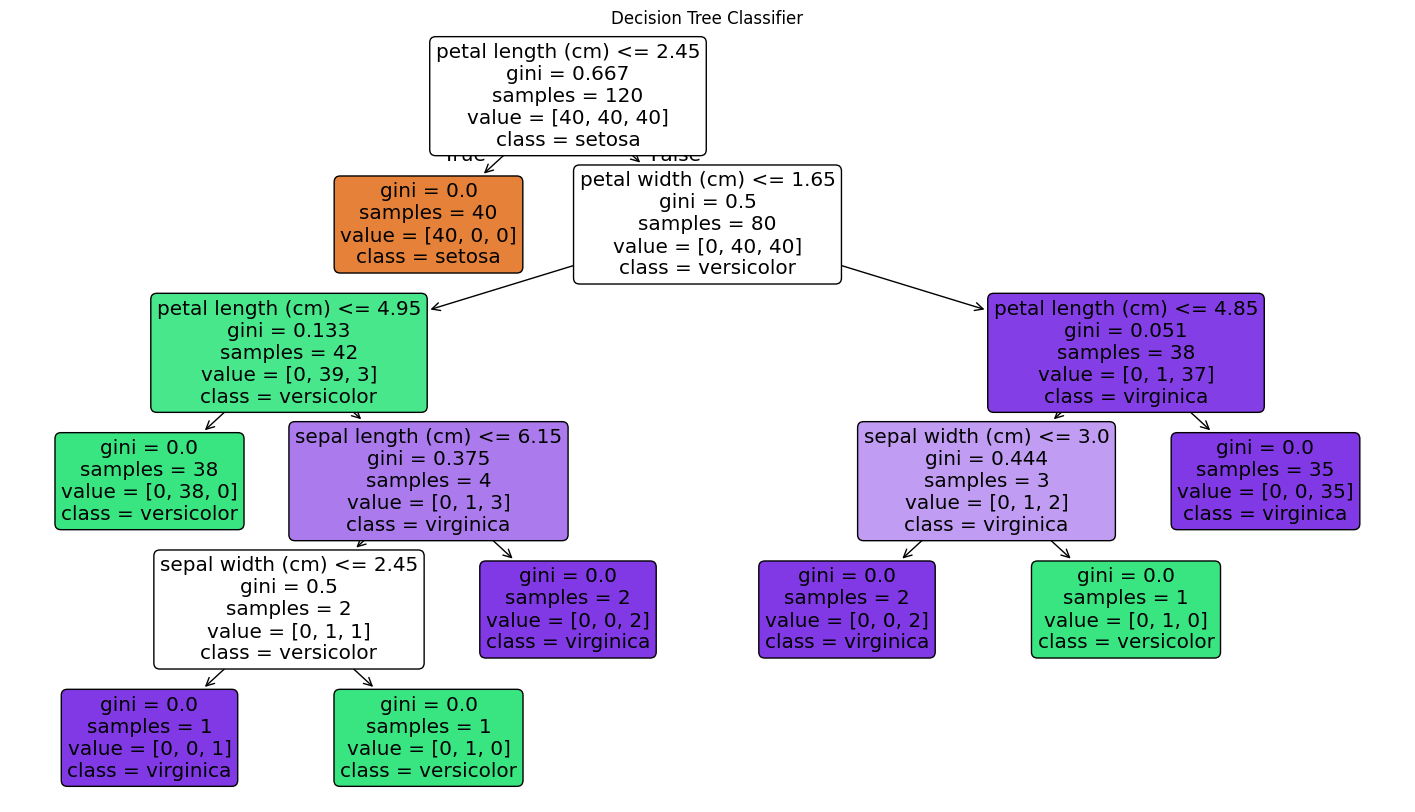

In [5]:


plt.figure(figsize=(18, 10))

plot_tree(
    dt_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier")
plt.show()


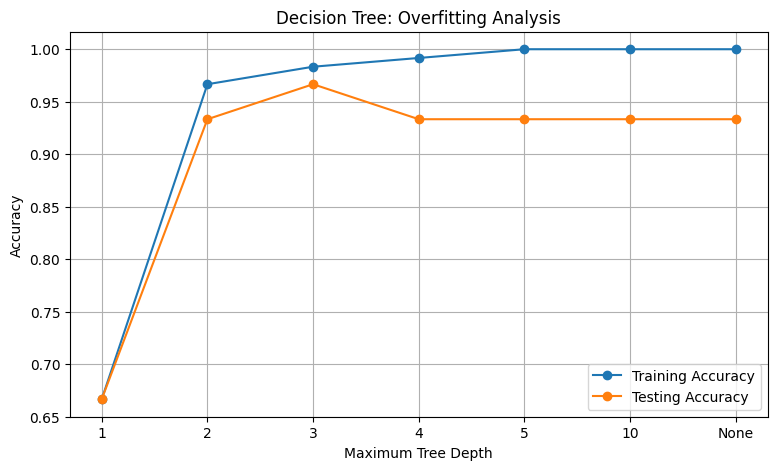

In [6]:

depths = [1, 2, 3, 4, 5, 10, None]
train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)

    train_accuracies.append(model.score(X_train, y_train))
    test_accuracies.append(model.score(X_test, y_test))

plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_accuracies, marker="o", label="Training Accuracy")
plt.plot(range(len(depths)), test_accuracies, marker="o", label="Testing Accuracy")
plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Overfitting Analysis")
plt.legend()
plt.grid(True)
plt.show()


In [7]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=iris.target_names
))


Random Forest Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [8]:

print("Decision Tree Accuracy:", round(dt_accuracy, 4))
print("Random Forest Accuracy:", round(rf_accuracy, 4))

if rf_accuracy > dt_accuracy:
    print("Random Forest performed better on this test set.")
elif dt_accuracy > rf_accuracy:
    print("Decision Tree performed better on this test set.")
else:
    print("Both models achieved the same test accuracy.")


Decision Tree Accuracy: 0.9333
Random Forest Accuracy: 0.9
Decision Tree performed better on this test set.


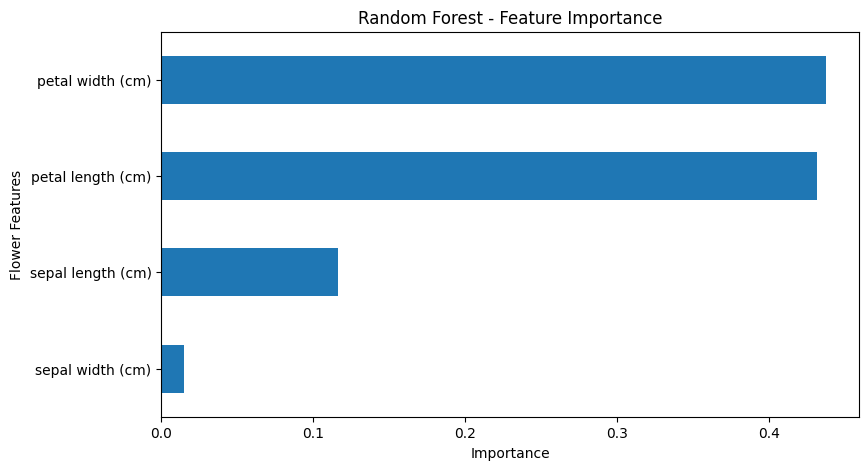

petal width (cm)     0.437185
petal length (cm)    0.431466
sepal length (cm)    0.116349
sepal width (cm)     0.015000
dtype: float64


In [9]:

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(9, 5))

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Flower Features")
plt.show()

print(importance.sort_values(ascending=False))


In [10]:

dt_cv_scores = cross_val_score(
    DecisionTreeClassifier(random_state=42),
    X, y,
    cv=5,
    scoring="accuracy"
)

rf_cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X, y,
    cv=5,
    scoring="accuracy"
)

print("Decision Tree CV scores:", dt_cv_scores)
print("Decision Tree Mean CV Accuracy:", round(dt_cv_scores.mean(), 4))

print("\nRandom Forest CV scores:", rf_cv_scores)
print("Random Forest Mean CV Accuracy:", round(rf_cv_scores.mean(), 4))


Decision Tree CV scores: [0.96666667 0.96666667 0.9        0.93333333 1.        ]
Decision Tree Mean CV Accuracy: 0.9533

Random Forest CV scores: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Random Forest Mean CV Accuracy: 0.9667


## Conclusion

In this task, I implemented Decision Tree and Random Forest classifiers using Python and Scikit-learn. I visualized the Decision Tree, analyzed overfitting by changing the maximum tree depth, compared the accuracy of both models, and examined Random Forest feature importance. I also evaluated both models using 5-fold cross-validation.

This task helped me understand tree-based classification, ensemble learning, model evaluation, and feature importance.